# Rossmann store sales: results and visualizations

Rossmann runs over a thousand drugstores. A planner needs to know roughly what each store will
sell **every day for the next 6 weeks** to schedule staff and order stock. This notebook shows
what the forecasting pipeline produces and how good it is, using only the saved results of
`rossmann run-all` (`reports/results.json` and `reports/viz_data/`). It needs no Kaggle files and
fits no models, so it runs in seconds.

How to read it: **WAPE** is total absolute error divided by total sales, so 8% means a typical
store-day forecast is off by about 8% of that day's sales. Forecasts are always made *before* the
window being predicted, using only older data.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.metrics import wape
from rossmann_forecast.viz_data import (
    load_forecasts,
    load_history,
    load_results,
    running_wape,
    store_wape_table,
)

from rossmann_forecast.plotting import find_root

ROOT = find_root()
results = load_results(ROOT / "reports" / "results.json")
forecasts = load_forecasts(ROOT / "reports" / "viz_data")
history = load_history(ROOT / "reports" / "viz_data")

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.alpha": 0.25,
        "axes.titleweight": "bold",
    }
)
NAMES = {
    "naive_last": "Naive (last day)",
    "snaive": "Seasonal naive (last week)",
    "snaive_mean4": "Mean of last 4 same weekdays",
    "last_year": "Same weekday last year",
    "random_forest": "Global Random Forest",
    "lightgbm": "Global LightGBM",
    "prophet_plain": "Prophet per store",
    "prophet_promo": "Prophet per store + promo",
}
COLORS = {
    "lightgbm": "#c0392b",
    "last_year": "#2e8b57",
    "snaive_mean4": "#8e6bbf",
    "random_forest": "#d98324",
    "prophet_promo": "#1f77b4",
    "prophet_plain": "#17becf",
    "snaive": "#7f7f7f",
    "naive_last": "#bcbd22",
}
models = results["all_stores"]
folds = {f["fold"]: f for f in results["folds"]}
fold_label = {k: f"{v['test_start']} to {v['test_end']}" for k, v in folds.items()}
horizon = results["meta"]["horizon_days"]
last_fold = max(folds)
print(
    f"{results['meta']['n_stores']:,} stores, {len(folds)} forecast windows of {horizon} days, "
    f"data {results['meta']['data_start']} to {results['meta']['data_end']}"
)

1,115 stores, 3 forecast windows of 42 days, data 2013-01-01 to 2015-07-31


## 1. Headline numbers

In [2]:
lgb = models["lightgbm"]["mean"]
baselines = [m for m in ("naive_last", "snaive", "snaive_mean4", "last_year") if m in models]
best = min(baselines, key=lambda m: models[m]["mean"]["wape"])
pd.DataFrame(
    {
        "value": [
            f"{lgb['wape'] * 100:.1f}%",
            f"{lgb['mae']:,.0f}",
            f"{models[best]['mean']['wape'] * 100:.1f}% ({NAMES[best]})",
            f"{(1 - lgb['wape'] / models[best]['mean']['wape']) * 100:.0f}%",
            f"{results['intervals']['90']['overall_coverage'] * 100:.1f}%",
        ]
    },
    index=[
        "Global LightGBM error (WAPE)",
        "Off by, sales per store per day",
        "Best simple baseline error",
        "Error reduction vs best baseline",
        "90% interval hit rate",
    ],
)

,value
Global LightGBM error (WAPE),9.2%
"Off by, sales per store per day",689
Best simple baseline error,18.9% (Mean of last 4 same weekdays)
Error reduction vs best baseline,51%
90% interval hit rate,86.4%


## 2. How the models compare

Bars show the mean over the three forecast windows, whiskers one standard deviation. Every model
has to beat the simple rules a planner could apply by hand.

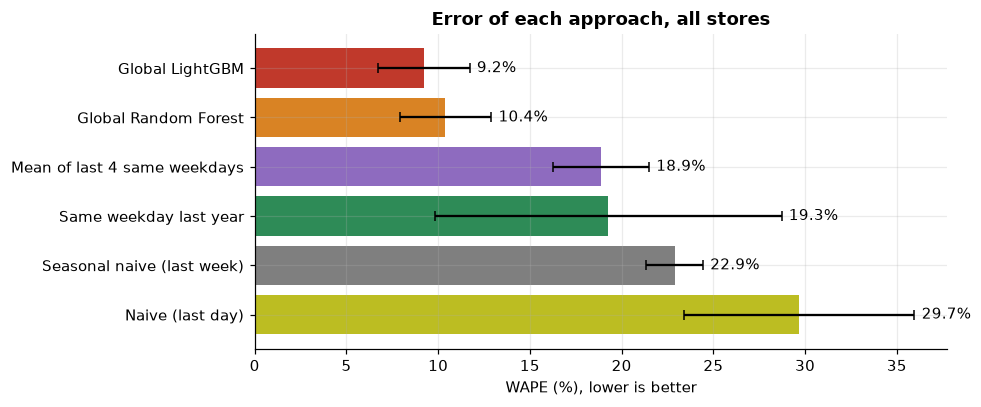

In [3]:
order = [m for m in NAMES if m in models and not m.startswith("prophet")]
order.sort(key=lambda m: -models[m]["mean"]["wape"])
fig, ax = plt.subplots(figsize=(9, 3.8))
vals = [models[m]["mean"]["wape"] * 100 for m in order]
errs = [models[m]["std"]["wape"] * 100 for m in order]
ax.barh([NAMES[m] for m in order], vals, xerr=errs, color=[COLORS[m] for m in order], capsize=3)
for i, v in enumerate(vals):
    ax.text(v + errs[i] + 0.4, i, f"{v:.1f}%", va="center")
ax.set_xlabel("WAPE (%), lower is better")
ax.set_title("Error of each approach, all stores")
fig.tight_layout()
plt.show()

In [4]:
sample = results["sample_stores"]
n = results["meta"]["n_prophet_stores"]
rows = ["snaive_mean4", "last_year", "prophet_plain", "prophet_promo", "random_forest", "lightgbm"]
pd.DataFrame(
    {
        "WAPE": [f"{sample[m]['mean']['wape'] * 100:.1f}%" for m in rows],
        "RMSE": [f"{sample[m]['mean']['rmse']:,.0f}" for m in rows],
    },
    index=[NAMES[m] for m in rows],
).rename_axis(f"Same {n} stores, same days")

,WAPE,RMSE
"Same 100 stores, same days",,
Mean of last 4 same weekdays,19.3%,"1,990"
Same weekday last year,19.5%,"2,052"
Prophet per store,17.9%,"1,818"
Prophet per store + promo,12.5%,"1,383"
Global Random Forest,10.8%,"1,324"
Global LightGBM,9.4%,"1,124"


Prophet is fitted separately for every store and window, so it ran on a random sample of stores.
One global LightGBM covers all stores in a single fit and beats it, even when Prophet is given the
promo calendar and holidays.

## 3. The same story in every window

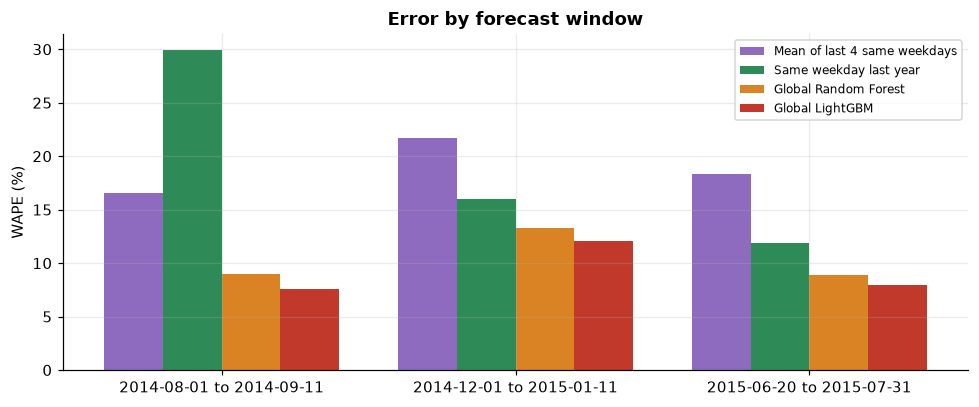

In [5]:
show = ["snaive_mean4", "last_year", "random_forest", "lightgbm"]
x = np.arange(len(folds))
fig, ax = plt.subplots(figsize=(9, 3.8))
width = 0.2
for j, m in enumerate(show):
    vals = [pf["wape"] * 100 for pf in models[m]["per_fold"]]
    ax.bar(x + (j - 1.5) * width, vals, width, label=NAMES[m], color=COLORS[m])
ax.set_xticks(x, [fold_label[k] for k in folds])
ax.set_ylabel("WAPE (%)")
ax.set_title("Error by forecast window")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

December is the hardest window for everyone because Christmas trading is spiky. Last year's
same weekday is strong in December but weak in August, because last year's promo weeks do not
line up with this year's.

## 4. Real forecasts, store by store

Each chart shows one store in the final window: grey is the sales history the forecast was made
from, black is what actually happened, red is the forecast with its 90% interval, and the green
dotted line is last year's sales on the same weekday.

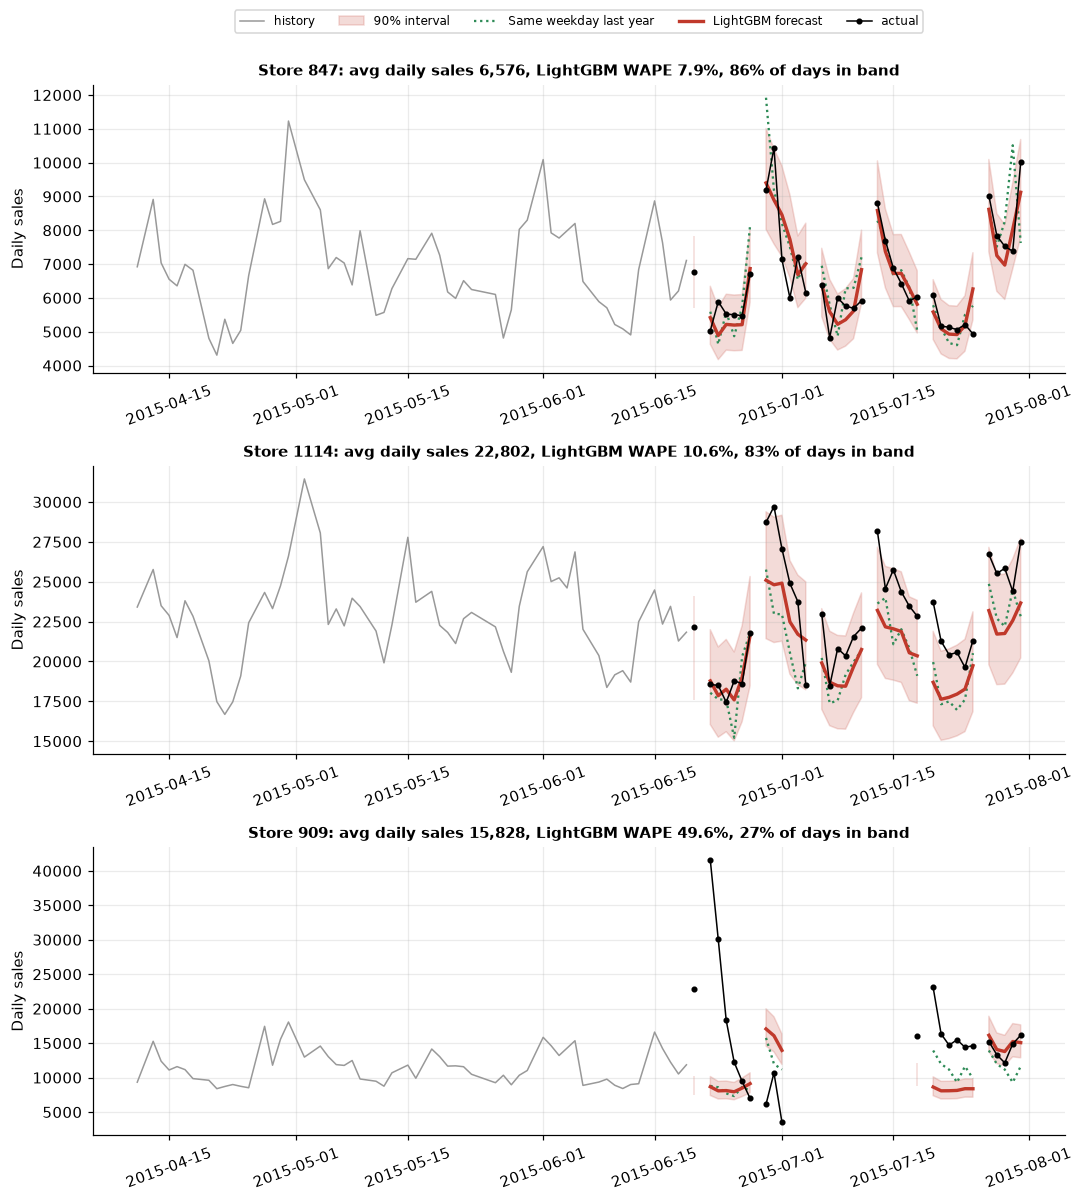

In [6]:
def plot_store(store, fold, ax, level=90, extras=("last_year",)):
    g = forecasts[(forecasts["fold"] == fold) & (forecasts["store_id"] == store)].sort_values("date")
    g = g.set_index("date").reindex(pd.date_range(g["date"].min(), g["date"].max())).rename_axis("date").reset_index()
    h = history[(history["fold"] == fold) & (history["store_id"] == store)].sort_values("date")
    ax.plot(h["date"], h["sales"], color="#999", lw=1, label="history")
    ax.fill_between(
        g["date"], g[f"lo{level}"], g[f"hi{level}"], color="#c0392b", alpha=0.18, label=f"{level}% interval"
    )
    for m in extras:
        ax.plot(g["date"], g[m], color=COLORS[m], ls=":", label=NAMES[m])
    ax.plot(g["date"], g["lightgbm"], color=COLORS["lightgbm"], lw=2.2, label="LightGBM forecast")
    ax.plot(g["date"], g["y"], "o-", color="black", ms=3, lw=1, label="actual")
    scored = g.dropna(subset=["y"])
    inside = ((scored["y"] >= scored[f"lo{level}"]) & (scored["y"] <= scored[f"hi{level}"])).mean()
    ax.set_title(
        f"Store {store}: avg daily sales {scored['y'].mean():,.0f}, "
        f"LightGBM WAPE {wape(scored['y'], scored['lightgbm']) * 100:.1f}%, {inside * 100:.0f}% of days in band",
        fontsize=10,
    )
    ax.set_ylabel("Daily sales")
    ax.tick_params(axis="x", rotation=20)


last = forecasts[forecasts["fold"] == last_fold]
volume = last.groupby("store_id")["y"].mean().sort_values()
table = store_wape_table(forecasts)
table = table[table["fold"] == last_fold]
typical = int(volume.index[len(volume) // 2])
busiest = int(volume.index[-1])
hard = int(table.loc[table[table["mean_sales"] > volume.median()]["wape"].idxmax(), "store_id"])
fig, axes = plt.subplots(3, 1, figsize=(10, 11), sharey=False)
for ax, store in zip(axes, [typical, busiest, hard], strict=True):
    plot_store(store, last_fold, ax)
axes[0].legend(ncol=5, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, 1.28))
fig.tight_layout()
plt.show()

Top: a typical store. Middle: the busiest store. Bottom: one of the hardest big stores to
forecast, shown on purpose so the weak spots are visible.

## 5. Replay: how the forecast held up as days passed

The forecast is fixed on day 0 for the whole chain (all stores added together). Reading left to
right, real sales arrive and the running error of each method is updated.

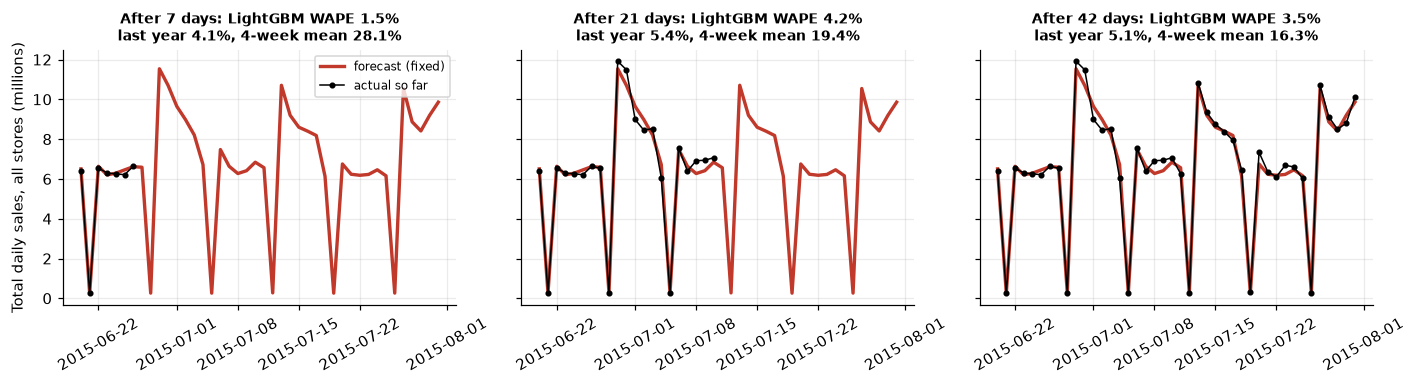

In [7]:
total = (
    forecasts[forecasts["fold"] == last_fold]
    .groupby("date")[["y", "lightgbm", "last_year", "snaive_mean4"]]
    .sum()
    .reset_index()
)
start = total["date"].min()
days = [7, 21, horizon]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, day in zip(axes, days, strict=True):
    seen = total[(total["date"] - start).dt.days < day]
    ax.plot(total["date"], total["lightgbm"] / 1e6, color=COLORS["lightgbm"], lw=2.2, label="forecast (fixed)")
    ax.plot(seen["date"], seen["y"] / 1e6, "o-", color="black", ms=3, lw=1, label="actual so far")
    ax.set_title(
        f"After {day} days: LightGBM WAPE {running_wape(total, 'lightgbm', day) * 100:.1f}%\n"
        f"last year {running_wape(total, 'last_year', day) * 100:.1f}%, "
        f"4-week mean {running_wape(total, 'snaive_mean4', day) * 100:.1f}%",
        fontsize=9,
    )
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Total daily sales, all stores (millions)")
axes[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

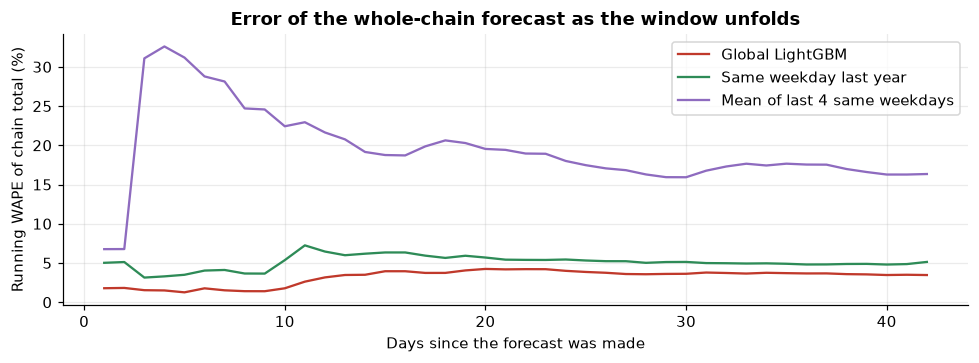

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
for m in ("lightgbm", "last_year", "snaive_mean4"):
    curve = [running_wape(total, m, d) * 100 for d in range(1, horizon + 1)]
    ax.plot(range(1, horizon + 1), curve, label=NAMES[m], color=COLORS[m])
ax.set_xlabel("Days since the forecast was made")
ax.set_ylabel("Running WAPE of chain total (%)")
ax.set_title("Error of the whole-chain forecast as the window unfolds")
ax.legend()
fig.tight_layout()
plt.show()

## 6. Where the forecast is good and where it is not

A good average can hide bad stores, so this is every store's error in every window.

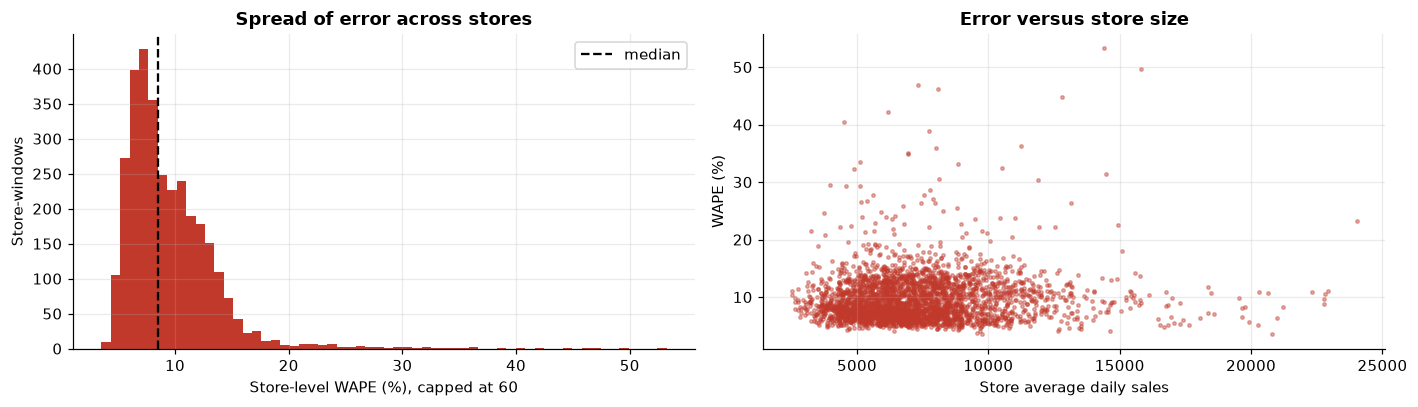

In [9]:
allw = store_wape_table(forecasts)
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].hist(allw["wape"].clip(upper=0.6) * 100, bins=60, color=COLORS["lightgbm"])
axes[0].axvline(allw["wape"].median() * 100, color="black", ls="--", label="median")
axes[0].set_xlabel("Store-level WAPE (%), capped at 60")
axes[0].set_ylabel("Store-windows")
axes[0].legend()
axes[0].set_title("Spread of error across stores")
axes[1].scatter(allw["mean_sales"], allw["wape"] * 100, s=5, alpha=0.4, color=COLORS["lightgbm"])
axes[1].set_xlabel("Store average daily sales")
axes[1].set_ylabel("WAPE (%)")
axes[1].set_title("Error versus store size")
fig.tight_layout()
plt.show()

In [10]:
worst = (
    allw.groupby("store_id")
    .agg(wape=("wape", "mean"), mean_sales=("mean_sales", "mean"))
    .sort_values("wape", ascending=False)
    .head(10)
)
worst["wape"] = (worst["wape"] * 100).round(1)
worst["mean_sales"] = worst["mean_sales"].round(0)
worst.rename(columns={"wape": "WAPE (%)", "mean_sales": "avg daily sales"})

,WAPE (%),avg daily sales
store_id,,
192,30.3,13759.0
909,29.8,13918.0
820,26.0,12407.0
306,23.9,4607.0
1056,23.1,4891.0
169,22.3,6292.0
279,22.3,10863.0
977,22.3,4508.0
292,22.0,6386.0


## 7. Prediction intervals: how sure is the forecast?

Each forecast comes with a band that should contain the actual sales most of the time. Here is how
often it really did, compared with the promise. The bands are split-conformal intervals calibrated
on the window just before each forecast.

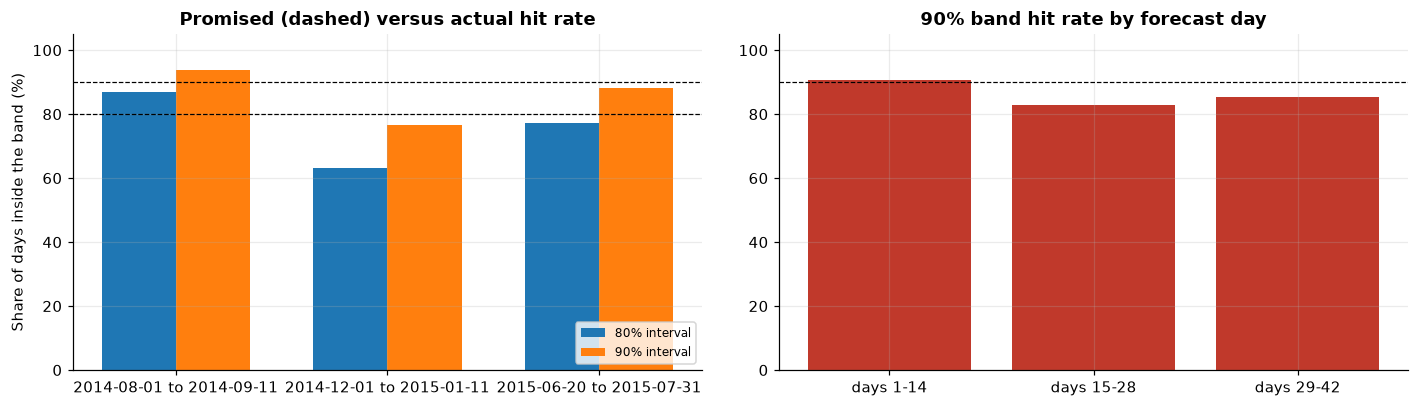

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
x = np.arange(len(folds))
for j, tag in enumerate(("80", "90")):
    block = results["intervals"][tag]
    vals = [p["coverage"] * 100 for p in block["per_fold"]]
    axes[0].bar(x + (j - 0.5) * 0.35, vals, 0.35, label=f"{tag}% interval")
    axes[0].axhline(int(tag), color="black", ls="--", lw=0.8)
axes[0].set_xticks(x, [fold_label[k] for k in folds])
axes[0].set_ylim(0, 105)
axes[0].set_ylabel("Share of days inside the band (%)")
axes[0].set_title("Promised (dashed) versus actual hit rate")
axes[0].legend(loc="lower right", fontsize=8)
hz = results["intervals"]["90"]["coverage_by_horizon"]
axes[1].bar(list(hz), [v * 100 for v in hz.values()], color="#c0392b")
axes[1].axhline(90, color="black", ls="--", lw=0.8)
axes[1].set_ylim(0, 105)
axes[1].set_title("90% band hit rate by forecast day")
fig.tight_layout()
plt.show()

The December window under-covers: the interval assumes the next window behaves like the last
one, which fails around Christmas. The measured hit rates are reported as they are.

## 8. Promotions and what drives the forecast

**These are associations, not proven causal effects.** Rossmann ran one promo calendar (alternate
weeks) for the whole chain, so there is no same-day control group.

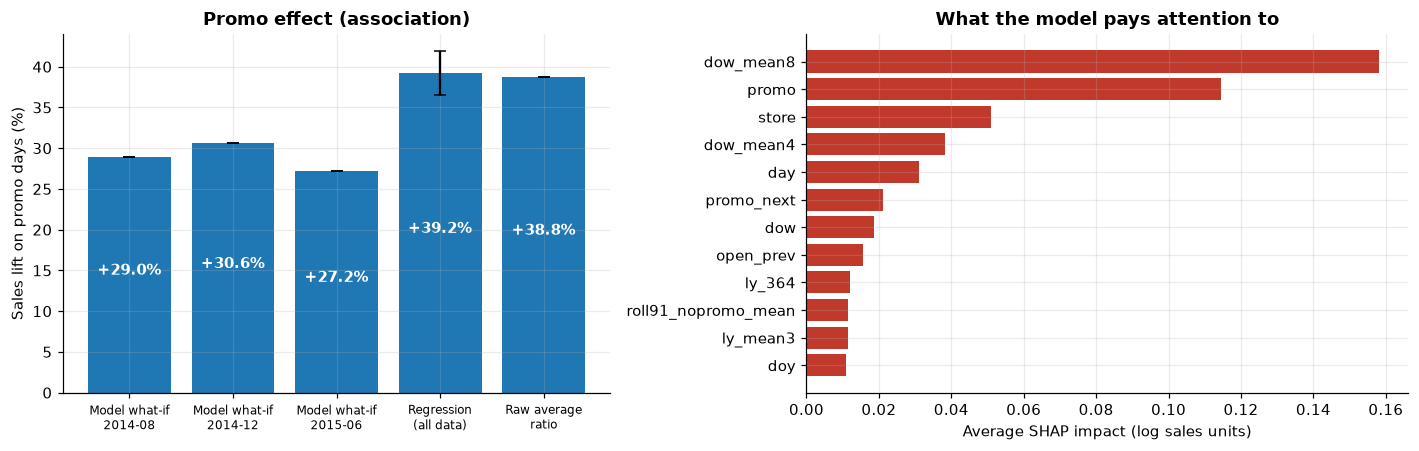

In [12]:
fe = results["promo_fixed_effects"]
cf = results["promo_model_counterfactual"]
labels = [f"Model what-if\n{fold_label[r['fold']][:7]}" for r in cf] + ["Regression\n(all data)", "Raw average\nratio"]
vals = [r["lift_pct"] for r in cf] + [fe["lift_pct"], fe["naive_ratio_lift_pct"]]
lower = [0] * len(cf) + [fe["lift_pct"] - fe["ci95_low_pct"], 0]
upper = [0] * len(cf) + [fe["ci95_high_pct"] - fe["lift_pct"], 0]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.1]})
axes[0].bar(labels, vals, yerr=[lower, upper], capsize=4, color="#1f77b4")
for i, v in enumerate(vals):
    axes[0].text(i, v / 2, f"{v:+.1f}%", ha="center", color="white", fontweight="bold")
axes[0].set_ylabel("Sales lift on promo days (%)")
axes[0].set_title("Promo effect (association)")
axes[0].tick_params(axis="x", labelsize=8)
shap = pd.Series(results["shap_top"]).sort_values()
axes[1].barh(shap.index, shap.values, color="#c0392b")
axes[1].set_xlabel("Average SHAP impact (log sales units)")
axes[1].set_title("What the model pays attention to")
fig.tight_layout()
plt.show()

In [13]:
print(
    f"Regression interval (95%) clusters errors by calendar week ({fe['n_week_clusters']} weeks). "
    f"Shuffling which weeks are promo weeks {fe['n_permutations']} times never reproduced the real "
    f"effect (randomisation p = {fe['permutation_p_value']:.3f})."
)

Regression interval (95%) clusters errors by calendar week (135 weeks). Shuffling which weeks are promo weeks 100 times never reproduced the real effect (randomisation p = 0.010).


Recent same-weekday sales and the promo flag matter most to the model. SHAP explains the model's
predictions, not causes in the real world.

## What this does not show

* Three forecast windows from one chain over about 2.5 years, so the standard deviations across
  windows are rough.
* Promo calendars, holidays and open days for the forecast window are assumed known in advance.
* Prophet ran on a sample of stores, not all of them.

Full tables, the evaluation design and limitations are in `docs/RESULTS.md` and the README.